# Bank Note Authentication Using KNN Classification

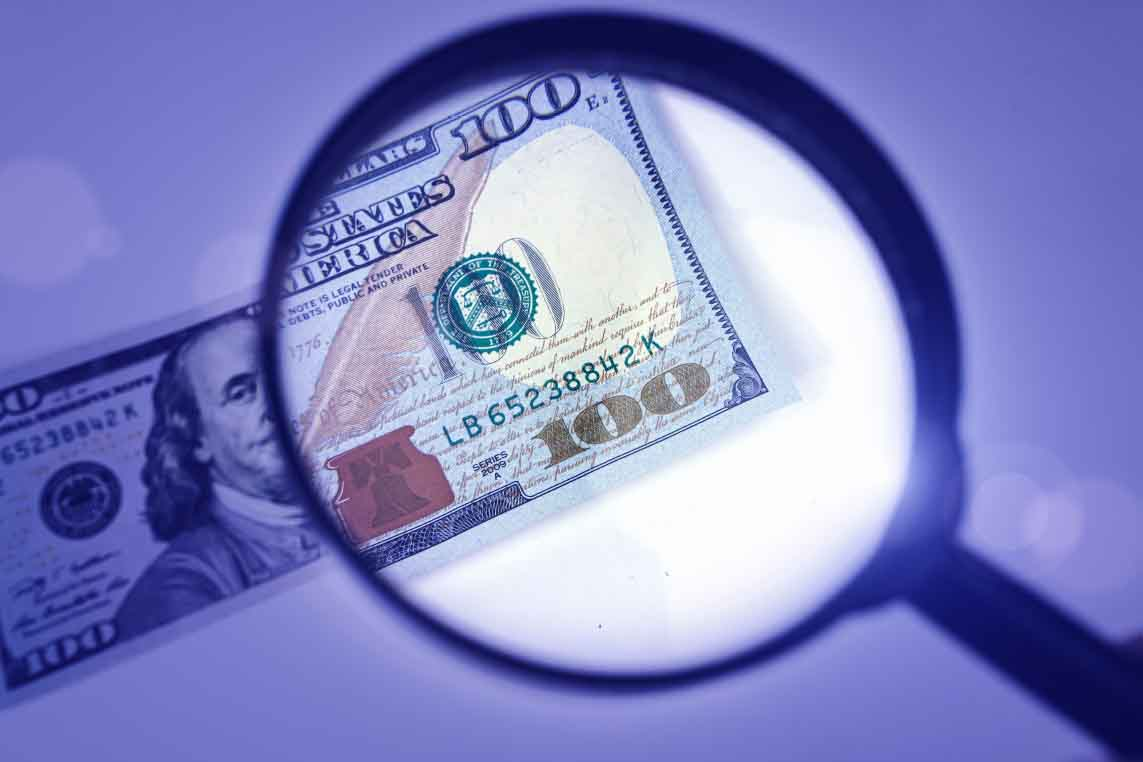

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
path = r"C:\Users\dg115\OneDrive\Documents\ML\banknote+authentication\data_banknote_authentication.txt"

In [4]:
df = pd.read_csv(path, header=None)

In [5]:
df.columns = ['Variance', 'Skewness', 'Curtosis', 'Entropy', 'Class']

In [6]:
df.head()

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [7]:
df.tail()

,Variance,Skewness,Curtosis,Entropy,Class
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [8]:
df.shape

(1372, 5)

In [9]:
df['Class'].value_counts()

Class
0    762
1    610
Name: count, dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [11]:
df.describe()

,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [12]:
df.isnull().sum()

Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(24)

In [14]:
df.drop_duplicates(inplace = True)

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
X = df.drop('Class', axis=1)
X.head()


,Variance,Skewness,Curtosis,Entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880


In [17]:
y = df['Class']
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64

In [18]:
print(X.shape)
print(y.shape)

(1348, 4)
(1348,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [20]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(1078, 4)
(270, 4)
(1078,)
(270,)


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [22]:
knn_hamming = KNeighborsClassifier(metric = "hamming")
knn_hamming

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'hamming'
,metric_params,None
,n_jobs,None


In [23]:
knn_hamming = knn_hamming.fit(X_train_scaled, y_train)
knn_hamming

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'hamming'
,metric_params,None
,n_jobs,None


In [24]:
y_pred_hamming = knn_hamming.predict(X_test_scaled)

In [25]:
result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_hamming
})

result.head(10)

,Actual,Predicted
0,0,1
1,1,1
2,0,1
3,0,1
4,1,0
5,0,1
6,0,1
7,0,0
8,0,1
9,1,1


In [26]:
from sklearn.metrics import accuracy_score 
accuracy_hamming = accuracy_score(y_test, y_pred_hamming)

print("Accuracy:", accuracy_hamming * 100, "%")

Accuracy: 46.666666666666664 %


In [27]:
knn_minkowski = KNeighborsClassifier(metric = "minkowski", p = 2)
knn_minkowski

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [28]:
knn_minkowski = knn_minkowski.fit(X_train_scaled, y_train)
knn_minkowski

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [29]:
y_pred_minkowski = knn_minkowski.predict(X_test_scaled)

In [30]:
accuracy_minkowski = accuracy_score(y_test, y_pred_minkowski)

print("Accuracy:", accuracy_minkowski * 100, "%")

Accuracy: 100.0 %


In [31]:
knn_manhattan = KNeighborsClassifier(metric = "manhattan")
knn_manhattan

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'manhattan'
,metric_params,None
,n_jobs,None


In [32]:
knn_manhattan = knn_manhattan.fit(X_train_scaled, y_train)
knn_manhattan

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'manhattan'
,metric_params,None
,n_jobs,None


In [33]:
y_pred_manhattan = knn_manhattan.predict(X_test_scaled)

In [34]:
accuracy_manhattan = accuracy_score(y_test, y_pred_manhattan)

print("Accuracy:", accuracy_manhattan * 100, "%")

Accuracy: 99.62962962962963 %


In [35]:
knn_chebyshev = KNeighborsClassifier(metric = "chebyshev")
knn_chebyshev

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'chebyshev'
,metric_params,None
,n_jobs,None


In [36]:
knn_chebyshev = knn_chebyshev.fit(X_train_scaled, y_train)
knn_chebyshev

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'chebyshev'
,metric_params,None
,n_jobs,None


In [37]:
y_pred_chebyshev = knn_chebyshev.predict(X_test_scaled)

In [38]:
accuracy_chebyshev = accuracy_score(y_test, y_pred_chebyshev)

print("Accuracy:", accuracy_chebyshev * 100, "%")

Accuracy: 100.0 %


In [39]:
accuracy_df = pd.DataFrame({
    'Distance Metric': ['Minkowski', 'Manhattan', 'Hamming', 'Chebyshev'],
    'Accuracy': [
        accuracy_minkowski * 100,
        accuracy_manhattan * 100,
        accuracy_hamming * 100,
        accuracy_chebyshev * 100
    ]
})

accuracy_df

,Distance Metric,Accuracy
0,Minkowski,100.000000
1,Manhattan,99.629630
2,Hamming,46.666667
3,Chebyshev,100.000000


In [40]:
result = pd.DataFrame({
    'Actual': y_test.map({0: 'Genuine', 1: 'Forged'}),
    'Predicted': pd.Series(y_pred_minkowski, index=y_test.index).map({0: 'Genuine', 1: 'Forged'})
})

result.head(10)

,Actual,Predicted
131,Genuine,Genuine
1164,Forged,Forged
168,Genuine,Genuine
14,Genuine,Genuine
977,Forged,Forged
538,Genuine,Genuine
356,Genuine,Genuine
584,Genuine,Genuine
591,Genuine,Genuine
868,Forged,Forged


In [41]:
new_data = [[0.6,1.34,-1.45,-0.5]]

new_data = scaler.transform(new_data)

prediction = knn_manhattan.predict(new_data)

if prediction[0] == 0:
    print("Predicted Class: Genuine")
else:
    print("Predicted Class: Forged")

Predicted Class: Forged
